# 01 · Basic Transmission Spectra

This notebook introduces the core `calculate()` API and shows how temperature
and magnetic field strength shape D-line transmission spectra.
All examples use the ES4 high-level interface via `elecsus_methods`.


In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from elecsus import elecsus_methods as em

from elecsus.libs.plot_style import apply_style, DURHAM_CYCLE
from elecsus.libs.plot_style import d_purple, d_blue, d_red, d_yellow, d_grey

apply_style()
import warnings
# calculate() returns complex arrays; for real-valued outputs (transmission,
# Stokes parameters) the imaginary part is ~0. Silence the cast-to-real warning
# when plotting - take .real explicitly if you need the numeric values.
warnings.filterwarnings('ignore', message='Casting complex values')
det = np.linspace(-10_000, 10_000, 1000)  # MHz


## Rb D2 — zero field, room temperature

At zero field all Zeeman sublevels are degenerate and the spectrum shows the
two hyperfine ground states (Rb-85 and Rb-87) as grouped absorption features.

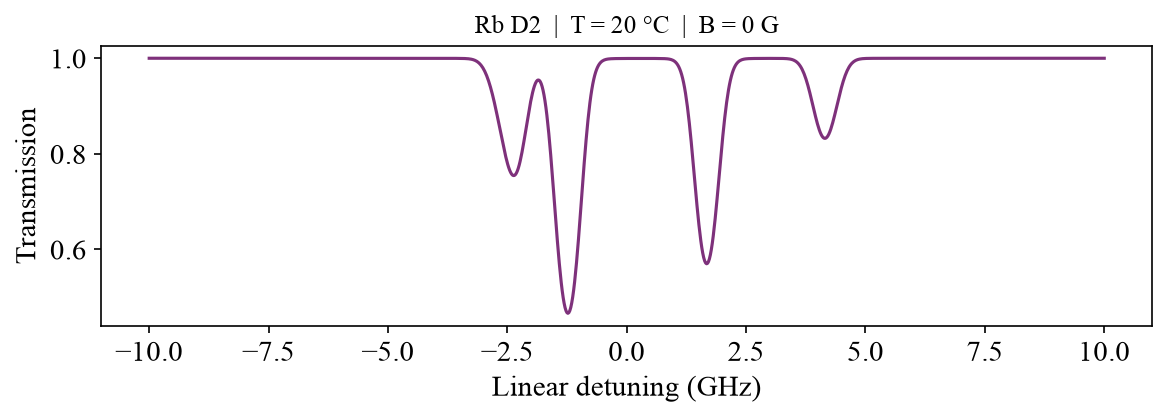

In [2]:
p = {'Elem': 'Rb', 'Dline': 'D2', 'T': 20., 'lcell': 75e-3, 'Bfield': 0}
[S0] = em.calculate(det, [1, 0, 0], p, outputs=['S0'])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(det / 1e3, S0)
ax.set(xlabel='Linear detuning (GHz)', ylabel='Transmission',
       title='Rb D2  |  T = 20 °C  |  B = 0 G')
plt.tight_layout()


## Effect of temperature

Number density scales exponentially with temperature, so even modest warming
drives the cell deep into saturation.  The Doppler width also broadens.

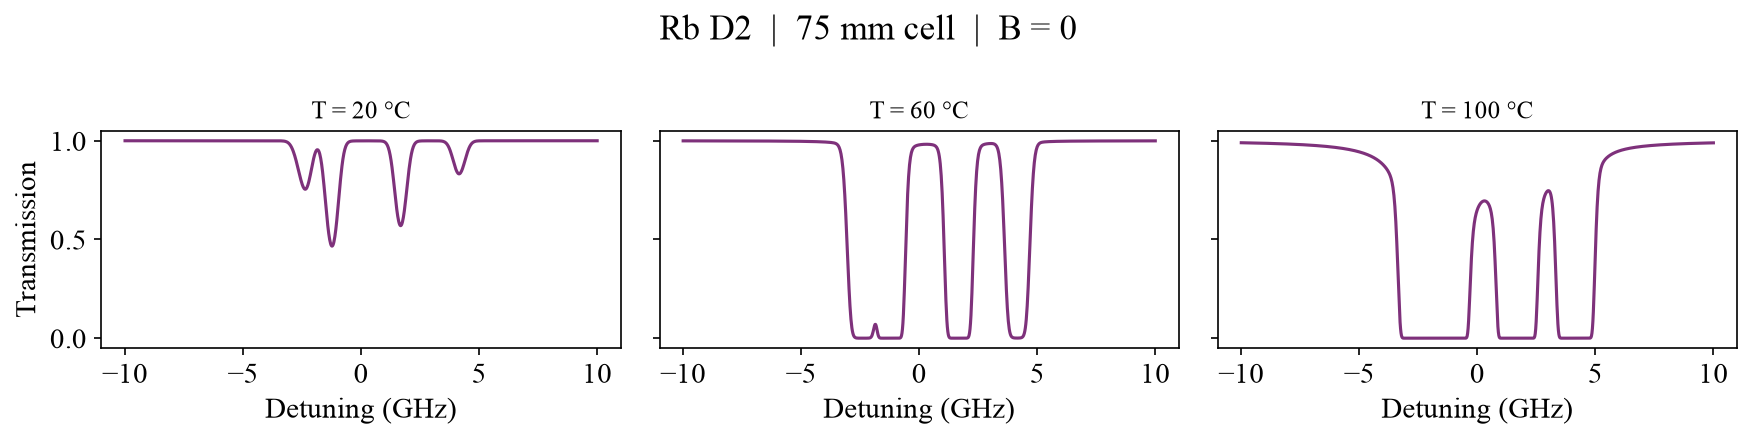

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, T in zip(axes, [20, 60, 100]):
    [S0] = em.calculate(det, [1,0,0],
                        {'Elem':'Rb','Dline':'D2','T':T,'lcell':75e-3},
                        outputs=['S0'])
    ax.plot(det / 1e3, S0)
    ax.set(xlabel='Detuning (GHz)', title=f'T = {T} °C')
axes[0].set_ylabel('Transmission')
fig.suptitle('Rb D2  |  75 mm cell  |  B = 0')
plt.tight_layout()


## Faraday geometry (B ∥ k)

A magnetic field along the propagation axis splits each transition into
σ⁺/σ⁻ components separated by the Zeeman shift.  At high fields the
spectrum resolves individual hyperfine transitions.

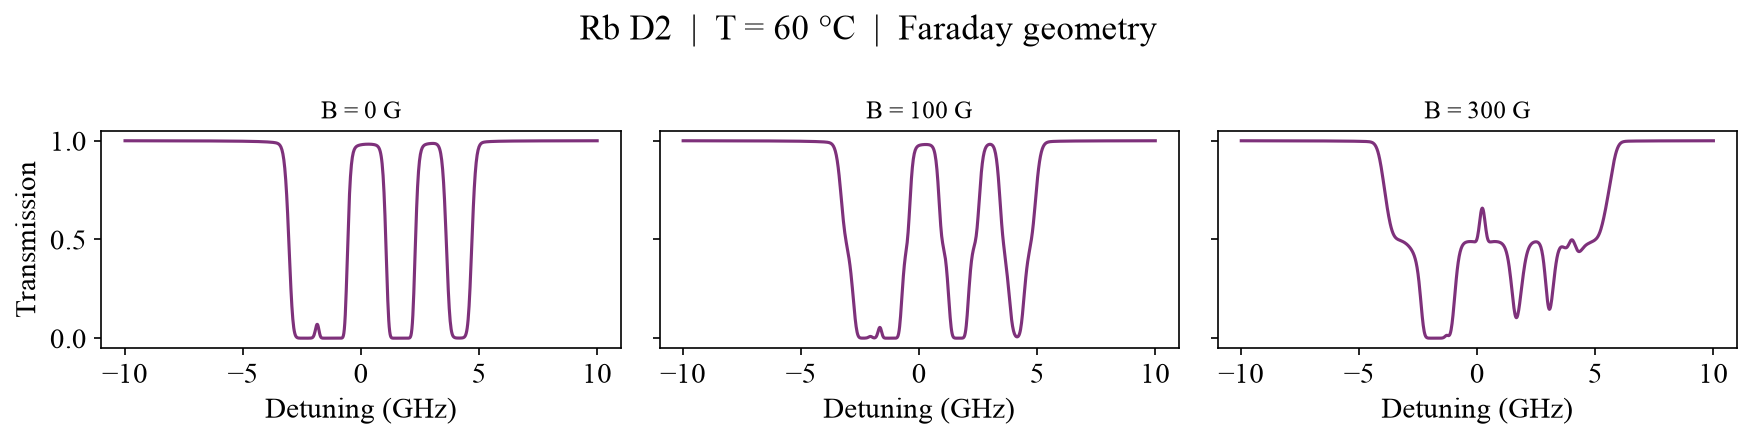

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, B in zip(axes, [0, 100, 300]):
    [S0] = em.calculate(det, [1,0,0],
                        {'Elem':'Rb','Dline':'D2','T':60.,'lcell':75e-3,'Bfield':B},
                        outputs=['S0'])
    ax.plot(det / 1e3, S0)
    ax.set(xlabel='Detuning (GHz)', title=f'B = {B} G')
axes[0].set_ylabel('Transmission')
fig.suptitle('Rb D2  |  T = 60 °C  |  Faraday geometry')
plt.tight_layout()


## D1 vs D2 lines

D1 connects S₁/₂ → P₁/₂; D2 connects S₁/₂ → P₃/₂.  The different excited-state
hyperfine splittings make D1 considerably simpler at low fields.

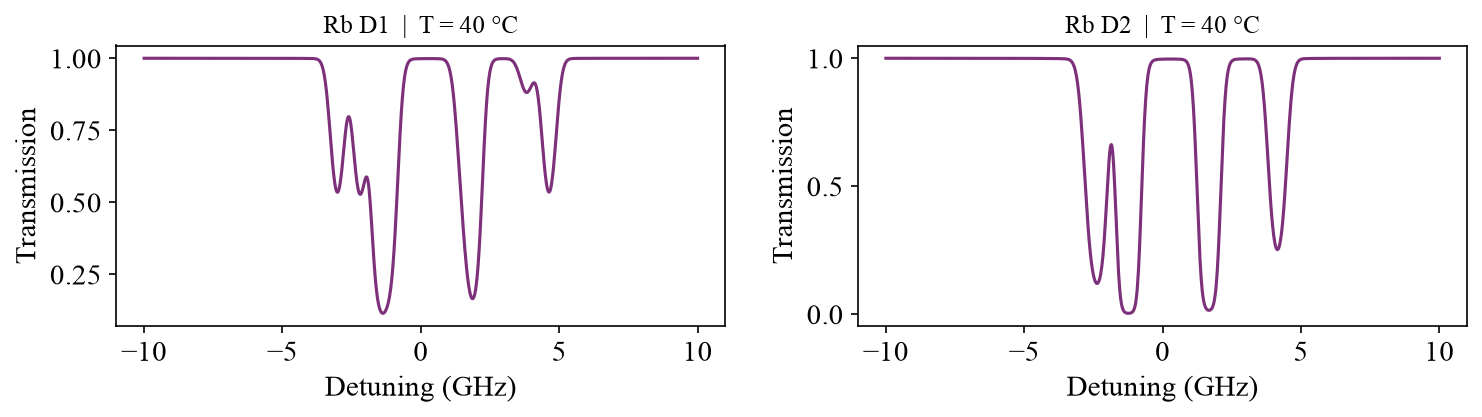

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, line in zip(axes, ['D1', 'D2']):
    [S0] = em.calculate(det, [1,0,0],
                        {'Elem':'Rb','Dline':line,'T':40.,'lcell':75e-3,'Bfield':0},
                        outputs=['S0'])
    ax.plot(det / 1e3, S0)
    ax.set(xlabel='Detuning (GHz)', ylabel='Transmission', title=f'Rb {line}  |  T = 40 °C')
plt.tight_layout()


## Other elements

ElecSus supports Na, K, Rb, Cs on both D lines.  Caesium has a single stable
isotope (¹³³Cs) and larger hyperfine splittings.

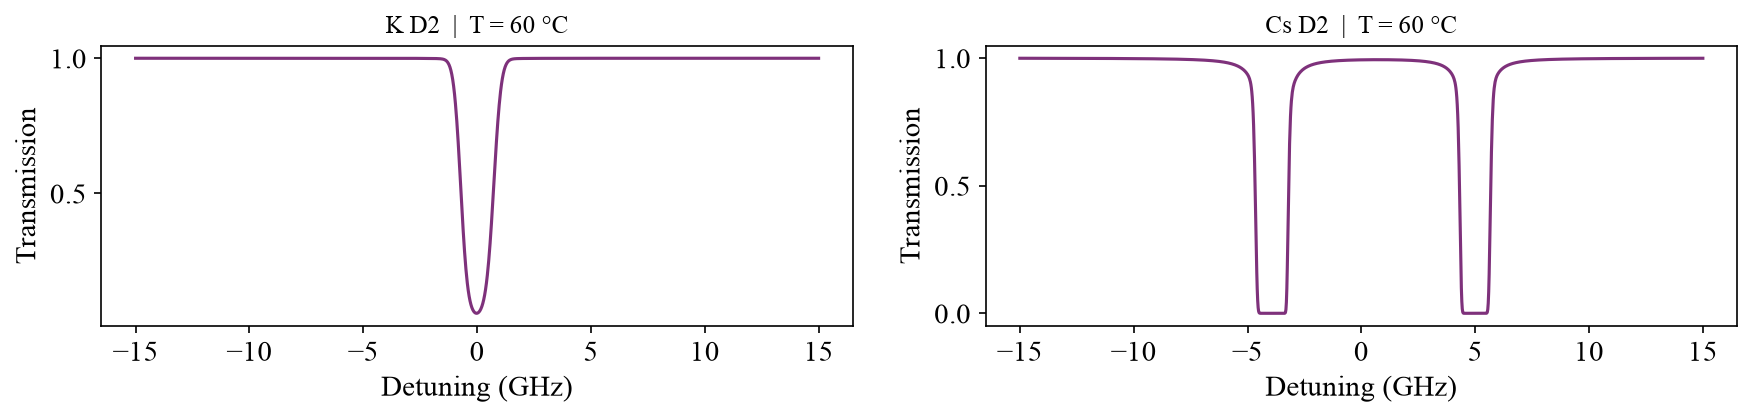

In [6]:
det_wide = np.linspace(-15_000, 15_000, 1500)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, elem in zip(axes, ['K', 'Cs']):
    [S0] = em.calculate(det_wide, [1,0,0],
                        {'Elem':elem,'Dline':'D2','T':60.,'lcell':75e-3,'Bfield':0},
                        outputs=['S0'])
    ax.plot(det_wide / 1e3, S0)
    ax.set(xlabel='Detuning (GHz)', ylabel='Transmission', title=f'{elem} D2  |  T = 60 °C')
plt.tight_layout()
